# Knowledge graphs: what we know, in a form a planner can read

Everything the search produces, and everything it designs against, is kept as a **typed graph with evidence**:

$$
G = (V, E), \qquad \tau_V : V \to \{\text{design}, \text{code move}, \text{submission}, \text{function}, \text{concept}, \text{instruction}\},
\qquad \tau_E : E \to \{\text{one-edit}, \text{touches}, \text{scored as}, \text{uses}, \text{is a}\}.
$$

Every measured node carries its values $J_\ell(v)$ per load $\ell$ **and how it was measured** (a 4-seed screen or a
12 × 2 confirm). Three queries do almost all the work:

1. **Neighbourhood** $N(v)$: what is one edit away from this design, and what did each edit do?
2. **Aggregate effect** of a field change $f: a \to b$, over all one-edit pairs that make it:
   $$\delta_\ell(f{:}\,a \to b) = \operatorname{median}_{(u, w)} \frac{J_\ell(w)}{J_\ell(u)} .$$
3. **Retrieval**: the $k$ nodes closest to a question, $\operatorname{top}_k\, \langle e(q), e(v) \rangle$ with unit
   embeddings $e$, read together with each node's evidence.

The picture below is a slice of the real graph around the shipped MoE design.

**Evidence and execution:** Recorded design observations with offline hashed retrieval; neighbourhood screens do not certify an optimum.

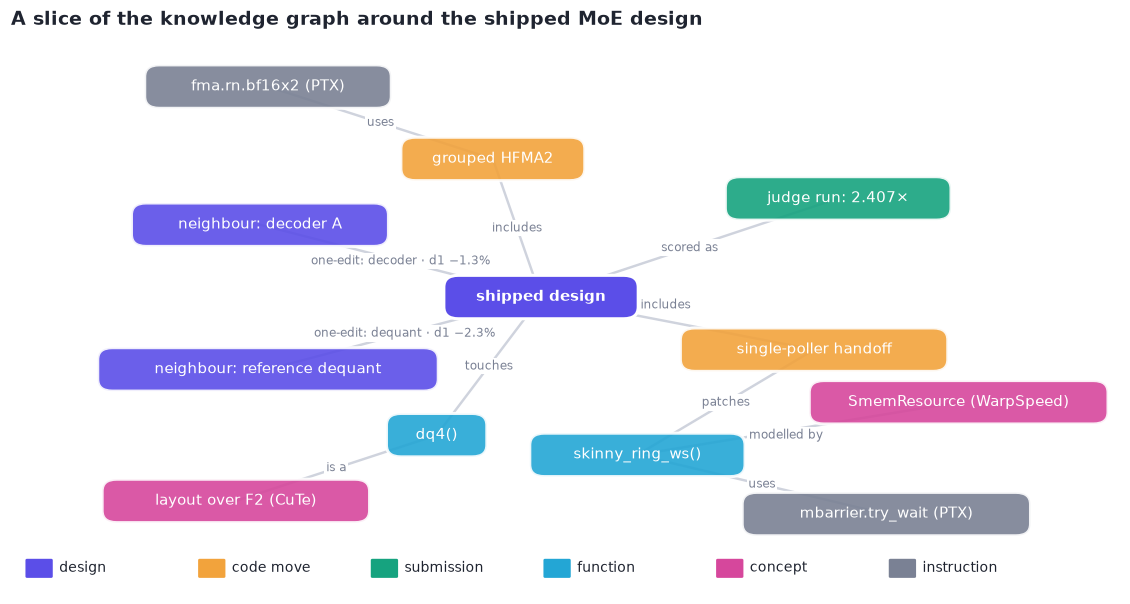

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd()
if not (ROOT / "xcalibur").is_dir():
    ROOT = ROOT.parent
sys.path[:0] = [str(ROOT), str(ROOT / "notebooks")]
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
import xcalibur as xc
from style import C, SEQ, MUTED, INK, DATA, save, note
from matplotlib.patches import FancyBboxPatch
TYPES = {"design": C["ours"], "code move": C["accent"], "submission": C["good"], "function": C["cyan"],
         "concept": C["pink"], "instruction": MUTED}
N = {"ship": ("shipped design", "design", 0, 0), "decA": ("neighbour: decoder A", "design", -3.5, 1.1),
     "dense": ("neighbour: reference dequant", "design", -3.4, -1.1), "judge": ("judge run: 2.407×", "submission", 3.7, 1.5),
     "hfma": ("grouped HFMA2", "code move", -0.6, 2.1), "hand": ("single-poller handoff", "code move", 3.4, -0.8),
     "dq4": ("dq4()", "function", -1.3, -2.1), "ring": ("skinny_ring_ws()", "function", 1.2, -2.4),
     "f2": ("layout over F2 (CuTe)", "concept", -3.8, -3.1), "ws": ("SmemResource (WarpSpeed)", "concept", 5.2, -1.6),
     "ptx1": ("fma.rn.bf16x2 (PTX)", "instruction", -3.4, 3.2), "ptx2": ("mbarrier.try_wait (PTX)", "instruction", 4.3, -3.3)}
EDGES = [("ship", "decA", "one-edit: decoder · d1 −1.3%"), ("ship", "dense", "one-edit: dequant · d1 −2.3%"),
         ("ship", "judge", "scored as"), ("ship", "hfma", "includes"), ("ship", "hand", "includes", (1.55, -0.12)), ("ship", "dq4", "touches"),
         ("hand", "ring", "patches"), ("dq4", "f2", "is a"), ("hfma", "ptx1", "uses"), ("ring", "ptx2", "uses"), ("ring", "ws", "modelled by", (3.05, -2.1))]
fig, ax = plt.subplots(figsize=(13, 6.6))
for e in EDGES:
    a, b, lab = e[:3]
    (_, _, xa, ya), (_, _, xb, yb) = N[a], N[b]
    lx, ly = e[3] if len(e) > 3 else ((xa + xb) / 2, (ya + yb) / 2)
    ax.plot([xa, xb], [ya, yb], color="#cfd3dd", lw=1.6, zorder=1)
    ax.text(lx, ly, lab, fontsize=8, color=MUTED, ha="center", va="center",
            bbox=dict(fc="white", ec="none", pad=1.2), zorder=2)
for k, (lab, t, x, y) in N.items():
    w = 0.13 * len(lab) + 0.5
    ax.add_patch(FancyBboxPatch((x - w / 2, y - 0.28), w, 0.56, boxstyle="round,pad=0.05,rounding_size=0.18",
                                fc=TYPES[t], ec="white", lw=2, zorder=3, alpha=1 if k == "ship" else 0.9))
    ax.text(x, y, lab, ha="center", va="center", color="white", fontsize=9.5, fontweight="bold" if k == "ship" else None, zorder=4)
for i, (t, cc) in enumerate(TYPES.items()):
    ax.add_patch(FancyBboxPatch((-6.4 + i * 2.15, -4.25), 0.3, 0.25, boxstyle="round,pad=0.02", fc=cc, ec="none"))
    ax.text(-6.0 + i * 2.15, -4.12, t, va="center", fontsize=9)
ax.set_xlim(-6.6, 7.2); ax.set_ylim(-4.5, 4.0); ax.axis("off")
ax.set_title("A slice of the knowledge graph around the shipped MoE design")
save(fig, "kg_slice"); plt.show()

## The design graph, built from the measured sweep

Each of the 514 screened designs becomes a node with three fields (dequant arithmetic, activation staging, decoder
graph). Edges join designs that differ in exactly one field. Decoder IDs are shortened here; the shipped decoder is
`B`, the one from notebook 04's interaction is `A`.

In [2]:
sw = pd.read_csv(DATA / "moe_sweep.csv"); scr = sw[sw.grade == "screen_4x1"].reset_index(drop=True)
L = ("d1", "d16", "d32", "v1", "v16", "v32")
short = {"1246039045:0": "B", "1683507725:1": "A"}
for i, d in enumerate(sorted(set(scr.decoder) - set(short))): short[d] = f"d{i:03d}"
g = xc.DesignGraph(loads=L)
for i, r in scr.iterrows():
    g.add(xc.Node(id=f"n{i}", kind="design", fields={"compute": r.compute, "activation": r.activation, "decoder": short[r.decoder]},
                  loads={l: r[l] for l in L}, evidence="screen 4x1"))
edges = g.one_edit()
print(f"{len(g.nodes)} nodes, {len(edges):,} one-edit edges")
print("\nWhat a planner reads (the first lines of g.listing()):\n")
print("\n".join(g.listing().splitlines()[:5]))

514 nodes, 78,301 one-edit edges

What a planner reads (the first lines of g.listing()):



# nodes [514] (per-load % vs reference, order d1/d16/d32/v1/v16/v32)
n0 design compute=hfma2_group_d1,activation=register,decoder=B [+6.4/+1.3/+1.3/+1.2/+0.4/+0.1] screen 4x1
n1 design compute=hfma2_group_d1,activation=register,decoder=d381 [-4.8/-4.3/-2.1/-4.5/-1.9/-3.2] screen 4x1
n2 design compute=hfma2_group_d1,activation=register,decoder=d075 [+0.9/-1.3/+0.9/-1.3/+0.6/-0.1] screen 4x1
n3 design compute=hfma2_group_d1,activation=register,decoder=d331 [+1.0/+0.5/+1.9/-0.9/+0.3/+1.0] screen 4x1


## Query 2: what each field change does, per load

The median effect of every one-field change away from the shipped values. No one told the graph which build each
field reaches, yet the table shows it: the dequant arithmetic and the activation staging move **decode 1** and leave
the other loads within noise, except `sparse_small`, which also moves decode 16 and verify 1, the small builds it is
compiled into. **The graph rediscovered the reach map from data** (the physical formulation derives the
same map from the code).

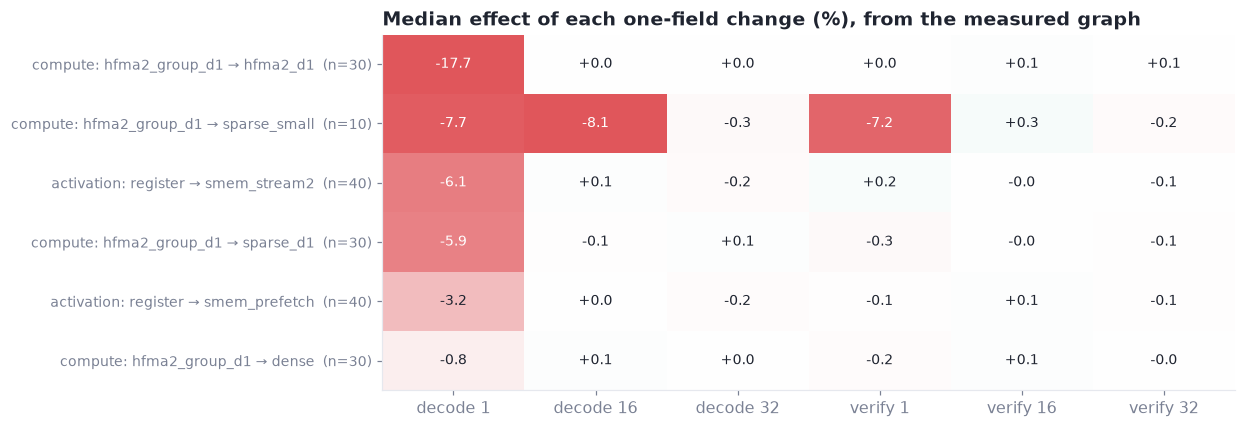

In [3]:
eff = [e for e in g.effects() if (e["field"], e["from"]) in (("compute", "hfma2_group_d1"), ("activation", "register"))]
eff = sorted(eff, key=lambda e: e["median"]["d1"])
M = np.array([[(e["median"][l] - 1) * 100 for l in L] for e in eff])
fig, ax = plt.subplots(figsize=(10, 4.2))
cm = plt.matplotlib.colors.LinearSegmentedColormap.from_list("div", [C["bad"], "#ffffff", C["good"]])
ax.imshow(np.clip(M, -8, 8), cmap=cm, vmin=-8, vmax=8, aspect="auto")
for (a, b), v in np.ndenumerate(M):
    ax.text(b, a, f"{v:+.1f}", ha="center", va="center", fontsize=9, color="white" if abs(v) > 5 else INK)
ax.set_xticks(range(6), ["decode 1", "decode 16", "decode 32", "verify 1", "verify 16", "verify 32"])
ax.set_yticks(range(len(eff)), [f"{e['field']}: {e['from']} → {e['to']}  (n={e['pairs']})" for e in eff], fontsize=9)
ax.grid(False); ax.set_title("Median effect of each one-field change (%), from the measured graph")
save(fig, "kg_effects"); plt.show()

## Query 1: the shipped design's neighbourhood

All 393 designs one decoder edit away from the shipped design, placed around it by their six-load effect. None reads
more than half a percent above it; 18 sit within noise; the rest are slower. Read from the graph, that is the
evidence that this screened neighbourhood has no resolved improvement. It does not certify a local optimum or replace confirmation.

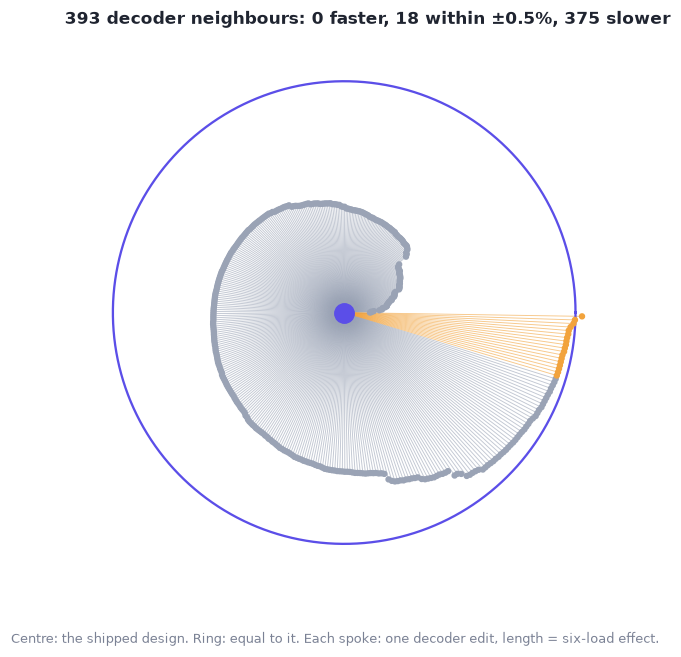

In [4]:
ship = next(n for n in g.nodes if n.fields == {"compute": "hfma2_group_d1", "activation": "register", "decoder": "B"})
nb = []
for a, b, k, x, y, r in edges:
    if k == "decoder" and ship.id in (a, b):
        v = np.exp(np.mean(np.log(list(r.values()))))
        nb.append((v if a == ship.id else 1 / v) - 1)
nb = np.sort(np.array(nb) * 100)
th = np.linspace(0, 2 * np.pi, len(nb), endpoint=False)
fig = plt.figure(figsize=(6.6, 6.6)); ax = fig.add_subplot(projection="polar")
r = 12 + nb
col = np.where(nb > 0.5, C["good"], np.where(nb >= -0.5, C["accent"], C["ref"]))
for t, rr, c in zip(th, r, col): ax.plot([t, t], [0, rr], color=c, lw=0.6, alpha=0.6)
ax.scatter(th, r, s=10, c=col, zorder=3)
ax.plot(np.linspace(0, 2 * np.pi, 200), np.full(200, 12), color=C["ours"], lw=1.5)
ax.scatter([0], [0], s=160, color=C["ours"], zorder=5)
ax.set_rticks([]); ax.set_xticks([]); ax.set_ylim(0, 14.5); ax.spines["polar"].set_visible(False)
ax.set_title(f"393 decoder neighbours: {int((nb > 0.5).sum())} faster, {int((abs(nb) <= 0.5).sum())} within ±0.5%, "
             f"{int((nb < -0.5).sum())} slower", fontsize=11)
fig.text(0.5, 0.04, "Centre: the shipped design. Ring: equal to it. Each spoke: one decoder edit, length = six-load effect.",
         ha="center", fontsize=8.5, color=MUTED)
save(fig, "kg_neighbourhood"); plt.show()

## Query 3: retrieval, and why evidence must ride along

Retrieval ranks nodes by similarity to a question. Similarity is not quality: the nearest nodes can be noisy screens
or designs for another build. So a context is built from **the compact listing** (the whole graph, one line per node),
**the top-$k$ nodes in full**, and **each node's evidence grade**, and exact checks still decide legality.

The embedding below is a hashed character-trigram stand-in so the notebook runs offline; in production we used
EmbeddingGemma with a code-retrieval prompt for queries (`xcalibur.embedding_gemma`).

In [5]:
import hashlib
def embed(texts, query=False, dim=512):
    out = []
    for t in texts:
        v = np.zeros(dim); t = f"  {t.lower()}  "
        for i in range(len(t) - 2): v[int(hashlib.md5(t[i:i + 3].encode()).hexdigest(), 16) % dim] += 1
        out.append(list(v / (np.linalg.norm(v) or 1)))
    return out
for n in g.nodes:
    n.text = (f"dequant {n.fields['compute']} activation {n.fields['activation']} decoder {n.fields['decoder']}; "
              f"one-token decode {100 * (n.loads['d1'] - 1):+.1f}%; measured as {n.evidence}")
ret = xc.Retriever(g.nodes, embed)
q = "faster one-token decode from a grouped hfma2 dequant with register activation"
rows = [{"node": n.id, "similarity": round(s, 3), **n.fields, "decode 1 (%)": round(100 * (n.loads["d1"] - 1), 1), "evidence": n.evidence}
        for n, s in ret.query(q, k=8)]
pd.DataFrame(rows)

,node,similarity,compute,activation,decoder,decode 1 (%),evidence
0,n214,0.662,hfma2_group_d1,register,d325,-6.0,screen 4x1
1,n306,0.655,hfma2_group_d1,register,d240,4.0,screen 4x1
2,n225,0.654,hfma2_group_d1,register,d082,-2.6,screen 4x1
3,n271,0.654,hfma2_group_d1,register,d027,-0.5,screen 4x1
4,n185,0.654,hfma2_group_d1,register,d222,-6.0,screen 4x1
5,n223,0.654,hfma2_group_d1,register,d365,-6.0,screen 4x1
6,n388,0.654,hfma2_group_d1,register,d065,-3.0,screen 4x1
7,n391,0.654,hfma2_group_d1,register,d120,-8.7,screen 4x1


[Notebook guide](README.md) · [Documentation](../docs/README.md#reading-order) · [Data provenance](../data/README.md)